# Chapter 13 — SIEM과 이벤트 상관 분석 (실습)

## 실습 목표
1. 다중 소스(방화벽·웹·SSH) 정규화
2. 시계열 윈도우 (brute force)
3. 시퀀스 매칭 (실패→성공)
4. 알람 그룹핑

In [1]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [2]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q pandas
# !pip install -q numpy

In [3]:
import pandas as pd
import numpy as np
rng = np.random.default_rng(42)

In [4]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

---
## Step 1. 다중 소스 → 공통 스키마 정규화

In [5]:
# 방화벽 로그 — 시각을 UTC 로 기록하는 장비
fw = pd.DataFrame({
    'time': pd.date_range('2024-07-05 10:00:00Z', periods=50, freq='2s'),
    'src_ip': ['10.0.0.99']*30 + ['10.0.0.5']*20,
    'dst_ip': ['10.0.0.50']*50,
    'action': ['blocked']*30 + ['allowed']*20,
})

# SSH 로그 — 같은 순간을 한국 시간(+0900) 문자열로 적는 서버
# 10:01:00 UTC == 19:01:00 +0900. 표기만 다르고 실제 시각은 같습니다.
ssh = pd.DataFrame({
    'timestamp': [(pd.Timestamp('2024-07-05 19:01:00') + pd.Timedelta(seconds=5*i))
                  .strftime('%d/%b/%Y:%H:%M:%S +0900') for i in range(15)],
    'source': ['10.0.0.99']*12 + ['10.0.0.7']*3,
    'target': ['10.0.0.50']*15,
    'result': ['failure']*11 + ['success']*4,
})

# 12장 12.4절에서 만든 normalize 와 같은 규약입니다. 소스를 늘릴 때는 분기만 추가합니다.
SOURCES = {
    'firewall': dict(ts='time',      fmt=None, src='src_ip', dst='dst_ip', detail='action'),
    'ssh':      dict(ts='timestamp', fmt='%d/%b/%Y:%H:%M:%S %z',
                     src='source',   dst='target', detail='result'),
}

def normalize(df, source: str) -> pd.DataFrame:
    """소스별 시각 표기를 UTC 로 맞추고 공통 열만 남깁니다(12장 12.4절과 동일 규약).
    파싱 실패는 정상 이벤트로 넘기지 않고 errors='raise' 로 즉시 드러냅니다."""
    if source not in SOURCES:
        raise ValueError(f'지원 소스: {", ".join(SOURCES)}. 다른 로그는 전용 파서를 추가한다.')
    spec = SOURCES[source]
    return pd.DataFrame({
        'ts': pd.to_datetime(df[spec['ts']], format=spec['fmt'], utc=True, errors='raise'),
        'src': df[spec['src']],
        'dst': df[spec['dst']],
        'event': source,
        'detail': df[spec['detail']],
    })

events = pd.concat([normalize(fw, 'firewall'), normalize(ssh, 'ssh')],
                   ignore_index=True).sort_values('ts').reset_index(drop=True)

# 정규화를 건너뛰면 두 소스가 9시간 어긋나 같은 시간창에 묶이지 않습니다.
print('정규화 후 시간대:', events['ts'].dt.tz, '| 전체 구간:',
      events['ts'].min().strftime('%H:%M:%S'), '~', events['ts'].max().strftime('%H:%M:%S'))
events.head(10)

정규화 후 시간대: UTC | 전체 구간: 10:00:00 ~ 10:02:10


,ts,src,dst,event,detail
0,2024-07-05 10:00:00+00:00,10.0.0.99,10.0.0.50,firewall,blocked
1,2024-07-05 10:00:02+00:00,10.0.0.99,10.0.0.50,firewall,blocked
2,2024-07-05 10:00:04+00:00,10.0.0.99,10.0.0.50,firewall,blocked
3,2024-07-05 10:00:06+00:00,10.0.0.99,10.0.0.50,firewall,blocked
4,2024-07-05 10:00:08+00:00,10.0.0.99,10.0.0.50,firewall,blocked
5,2024-07-05 10:00:10+00:00,10.0.0.99,10.0.0.50,firewall,blocked
6,2024-07-05 10:00:12+00:00,10.0.0.99,10.0.0.50,firewall,blocked
7,2024-07-05 10:00:14+00:00,10.0.0.99,10.0.0.50,firewall,blocked
8,2024-07-05 10:00:16+00:00,10.0.0.99,10.0.0.50,firewall,blocked
9,2024-07-05 10:00:18+00:00,10.0.0.99,10.0.0.50,firewall,blocked


---
## Step 2. 시계열 윈도우 — Brute Force

In [6]:
ssh_evt = events[(events['event']=='ssh') & (events['detail']=='failure')].set_index('ts')
rolling = ssh_evt.groupby('src')['detail'].rolling('1min').count()
brute = rolling[rolling >= 5]
print('--- Brute force (1min, >=5) ---')
print(brute)

--- Brute force (1min, >=5) ---
src        ts                       
10.0.0.99  2024-07-05 10:01:20+00:00     5.0
           2024-07-05 10:01:25+00:00     6.0
           2024-07-05 10:01:30+00:00     7.0
           2024-07-05 10:01:35+00:00     8.0
           2024-07-05 10:01:40+00:00     9.0
           2024-07-05 10:01:45+00:00    10.0
           2024-07-05 10:01:50+00:00    11.0
Name: detail, dtype: float64


---
## Step 3. 시퀀스 매칭 — 실패 후 성공

In [7]:
def detect_brute_then_success(df, window='2min', threshold=5):
    df = df[df['event']=='ssh'].sort_values('ts')
    alerts = []
    for src, g in df.groupby('src'):
        g = g.set_index('ts')
        fails = g[g['detail']=='failure']
        succs = g[g['detail']=='success']
        for t in succs.index:
            n = fails[(fails.index >= t - pd.Timedelta(window)) & (fails.index < t)].shape[0]
            if n >= threshold:
                alerts.append({'src': src, 'time': t, 'n_fails_before': n})
    return pd.DataFrame(alerts)

alerts = detect_brute_then_success(events)
print('--- Brute-then-success 알람 ---')
print(alerts)

--- Brute-then-success 알람 ---
         src                      time  n_fails_before
0  10.0.0.99 2024-07-05 10:01:55+00:00              11


---
## Step 4. 알람 그룹핑

In [8]:
# 같은 src 가 firewall blocked + ssh failure 둘 다 발생 → CRITICAL
summary = events.groupby('src').apply(
    lambda g: pd.Series({
        'fw_blocked': ((g['event']=='firewall') & (g['detail']=='blocked')).sum(),
        'ssh_failure': ((g['event']=='ssh') & (g['detail']=='failure')).sum(),
        'ssh_success': ((g['event']=='ssh') & (g['detail']=='success')).sum(),
    })
)
def correlate_multi_source(fw, ssh, window='1min'):
    a = fw.loc[fw['action'] == 'blocked', ['ts', 'src']].assign(fw=1, ssh=0)
    b = ssh.loc[ssh['result'] == 'failure', ['ts', 'src']].assign(fw=0, ssh=1)
    events = pd.concat([a, b], ignore_index=True)
    alerts = []
    for src, group in events.groupby('src'):
        # 같은 시각의 이벤트를 합쳐 두 소스에 동일한 (t-window, t]를 적용한다.
        counts = group.groupby('ts')[['fw', 'ssh']].sum().sort_index()
        counts = counts.rolling(window, closed='right').sum()
        hits = counts[(counts['fw'] >= 5) & (counts['ssh'] >= 3)]
        if not hits.empty:
            t = hits.index[0]
            alerts.append({'ts': t, 'src': src, 'fw_blocked': int(hits.loc[t, 'fw']),
                           'ssh_failed': int(hits.loc[t, 'ssh']), 'severity': 'HIGH'})
    return pd.DataFrame(alerts, columns=['ts', 'src', 'fw_blocked', 'ssh_failed', 'severity'])
fw_events = events[events['event']=='firewall'].rename(columns={'detail':'action'})
ssh_events = events[events['event']=='ssh'].rename(columns={'detail':'result'})
correlated = correlate_multi_source(fw_events, ssh_events)
summary['same_window'] = summary.index.isin(correlated['src'])
print(correlated)
# summary는 전체 기간 빈도이며, 시간 상관 판정은 correlated만 사용한다.


                         ts        src  fw_blocked  ssh_failed severity
0 2024-07-05 10:01:10+00:00  10.0.0.99          24           3     HIGH


/tmp/ipykernel_2107582/388991381.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = events.groupby('src').apply(


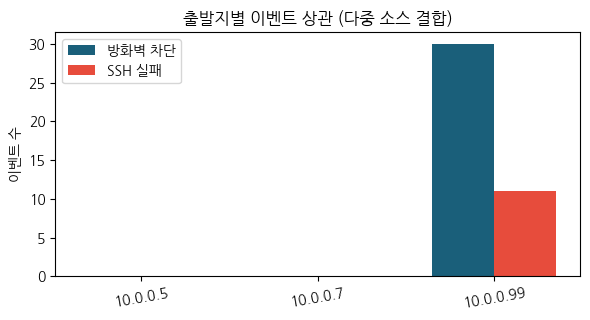

In [9]:
# 출발지별 이벤트 상관 — 방화벽 차단 + SSH 실패가 함께 튀는 src 가 위험
import matplotlib.pyplot as plt
import numpy as np
srcs = list(summary.index); x = np.arange(len(srcs)); w = 0.35
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.bar(x - w/2, summary['fw_blocked'], w, label='방화벽 차단', color='#1a5f7a')
ax.bar(x + w/2, summary['ssh_failure'], w, label='SSH 실패', color='#e74c3c')
ax.set_xticks(x); ax.set_xticklabels(srcs, rotation=10)
ax.set_title('출발지별 이벤트 상관 (다중 소스 결합)')
ax.set_ylabel('이벤트 수'); ax.legend()
plt.tight_layout(); plt.show()

---
## 정리

- 다중 소스를 같은 스키마로 정규화하는 것이 SIEM 의 핵심.
- pandas rolling 으로 시계열 임계값, 직접 함수로 시퀀스 매칭.
- 다음 챕터에서 본격 지도학습 모델로 분류한다 (ch14).